# Figure 2: A CRISPRa sc-multiome screen of 60 developmental TFs in mESCs
### Loading 60 TF multiome dataset
The following processed dataset:

`atac-rna.preprocessed-s4.signac.rds`

corresponds to:

`GSE353547_Screen60TF_Multiome_mESC_processed_signac.rds`

In [1]:
source("./load_packages.R")

In [2]:
obj <- readRDS("../data/atac-rna.preprocessed-s4.signac.rds")

targets <- sort(unique(obj@meta.data$target[obj@meta.data$target != "" & 
                                             obj@meta.data$target != "NTC" & 
                                             !grepl("_", obj@meta.data$target)]))

### Useful functions
Functions for running lochNESS on target cells, for gene expression, etc.

In [3]:
target_lochNESS <- function(obj, tf) {
    safe_column_scale = function(bmat, scale_vector) {
      bmat@x <- bmat@x / rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    safe_column_multiply = function(bmat, scale_vector) {
      bmat@x <- bmat@x * rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    kadj = round(0.5 * sqrt(ncol(obj)))

    # adding a "genotype" column that is "KO" for cbcs assigned e.g. a Cdx2 gRNA,
    # and "WT" for all other cells
    if (tf == "NTC") {
        obj@meta.data$genotype <- ifelse(obj@meta.data$target == "NTC", "KO", "WT")
    } else {
        obj@meta.data$genotype <- ifelse(grepl(paste0('(^|_)', tf, '(_|$)'), obj@meta.data$target) == TRUE, "KO", "WT")
    }

    # MT scores
    mt_counts = as.data.frame(table(obj$genotype))
    mutant_mask = ifelse(obj@meta.data$genotype=="WT", 0, 1)
    mutant_neighbors = Matrix::rowSums(safe_column_multiply(obj@graphs$tf.all.peaks_nn, mutant_mask))
    pca_mutant_score = (mutant_neighbors / kadj) / (1 - mt_counts$Freq[mt_counts$Var1=='WT'] / length(mutant_neighbors)) - 1

    # plotting
    mutant_score = pca_mutant_score
    df_umap = as.data.frame(obj[['TFallumap']]@cell.embeddings)

    df_umap$raw_mt_score = mutant_score

    bg1 = df_umap[obj$genotype=="WT",]
    dt1 = df_umap[obj$genotype!="WT",]
    
    df_umap$genotype <- obj@meta.data$genotype[match(rownames(df_umap), rownames(obj@meta.data))]
    df_umap
}

exp_lochNESS <- function(obj, gene) {
    safe_column_scale = function(bmat, scale_vector) {
      bmat@x <- bmat@x / rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    safe_column_multiply = function(bmat, scale_vector) {
      bmat@x <- bmat@x * rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    kadj = round(0.5 * sqrt(ncol(obj)))
    
    exp.df <- as.data.frame(GetAssayData(object = obj, assay = "RNA", slot = "data")[gene, ])
    names(exp.df)[1] <- 'exp'

    obj@meta.data$genotype <- ifelse(rownames(obj@meta.data) %in% rownames(exp.df[exp.df$exp >0,,drop=FALSE]), "KO", "WT")

    # MT scores
    mt_counts = as.data.frame(table(obj$genotype))
    mutant_mask = ifelse(obj@meta.data$genotype=="WT", 0, 1)
    mutant_neighbors = Matrix::rowSums(safe_column_multiply(obj@graphs$tf.all.peaks_nn, mutant_mask))
    pca_mutant_score = (mutant_neighbors / kadj) / (1 - mt_counts$Freq[mt_counts$Var1=='WT'] / length(mutant_neighbors)) - 1

    # plotting
    mutant_score = pca_mutant_score
    df_umap = as.data.frame(obj[['TFallumap']]@cell.embeddings)

    df_umap$raw_mt_score = mutant_score
    # df_umap$mt_score = scale(mutant_score, center = TRUE, scale = FALSE)

    bg1 = df_umap[obj$genotype=="WT",]
    dt1 = df_umap[obj$genotype!="WT",]
    
    df_umap$genotype <- obj@meta.data$genotype[match(rownames(df_umap), rownames(obj@meta.data))]
    df_umap
}

multiple_tf_umap_ordered <- function(tfs,umap_,c_pal,loch_type,loch_cutoff) {

    cbc_list <- list()
    color_list <- list()
    i <- 1
    
    meta <- obj@meta.data
    for (tf in tfs) {
      
      if (loch_type == "exp") {
          loch <- exp_lochNESS(obj, tf)
          
      } else {
          loch <- target_lochNESS(obj,tf)  
      }
        
      t.cells <- rownames(loch[loch$genotype == "KO" & loch$raw_mt_score > loch_cutoff,])    
    
      cbc_list[[tf]] <- t.cells
      color_list[[tf]] <- c_pal[i]
      i <- i + 1
    }

    all_cbcs <- unique(as.vector(unlist(cbc_list)))


    UMAP.df <- as.data.frame(obj[[umap_]]@cell.embeddings)
    colnames(UMAP.df) <- c("UMAP1", "UMAP2")
    UMAP.df$CBC <- row.names(UMAP.df)

    q <- ggplot() +
      geom_point_rast(data = UMAP.df[!(UMAP.df$CBC %in% all_cbcs), ], 
                 aes(x = UMAP1, y = UMAP2), color = "lightgrey", size = 0.01, alpha = 0.1) +
      theme_void() +
      theme(text = element_text(size = 8),
            plot.title = element_text(hjust = 0.5))

    for (i in seq_along(tfs)) {
      index_ <- tfs[i]
      cells <- cbc_list[[index_]]
      UMAP.df$group <- ifelse(UMAP.df$CBC %in% cells, tfs[i], "")

      q <- q + geom_point_rast(data = UMAP.df[(UMAP.df$CBC %in% cells), ], 
                          aes(x = UMAP1, y = UMAP2, fill = group, color = group), size = .05, alpha = 0.5)
    }

    q + scale_fill_manual(values = color_list, name = "") +
      scale_color_manual(values = color_list, name = "") +
      guides(colour=guide_legend(nrow=4,override.aes = list(size=3))) + 
      theme(legend.position="bottom")
    }



multiple_tf_umap_random <- function(tfs,umap_,c_pal,loch_type,loch_cutoff) {

    cbc_list <- list()
    color_list <- list()
    i <- 1
    
    meta <- obj@meta.data
    for (tf in tfs) {
      
      if (loch_type == "exp") {
          loch <- exp_lochNESS(obj, tf)
          
      } else {
          loch <- target_lochNESS(obj,tf)  
      }
        
      t.cells <- rownames(loch[loch$genotype == "KO" & loch$raw_mt_score > loch_cutoff,])    
    
      cbc_list[[tf]] <- t.cells
      color_list[[tf]] <- c_pal[i]
      i <- i + 1
    }

    all_cbcs <- unique(as.vector(unlist(cbc_list)))


    UMAP.df <- as.data.frame(obj[[umap_]]@cell.embeddings)
    colnames(UMAP.df) <- c("UMAP1", "UMAP2")
    UMAP.df$CBC <- row.names(UMAP.df)

    q <- ggplot() +
      geom_point_rast(data = UMAP.df[!(UMAP.df$CBC %in% all_cbcs), ], 
                 aes(x = UMAP1, y = UMAP2), color = "lightgrey", size = 0.01, alpha = 0.5) +
      theme_void() +
      theme(text = element_text(size = 8),
            plot.title = element_text(hjust = 0.5))
    
    fin.df <- as.data.frame(matrix(ncol=0,nrow=0))
    
    for (i in seq_along(tfs)) {
      index_ <- tfs[i]
      cells <- cbc_list[[index_]]
      UMAP.df$group <- ifelse(UMAP.df$CBC %in% cells, tfs[i], "")
        
      sub.df <- UMAP.df[(UMAP.df$CBC %in% cells), ]
      sub.df$group <- tfs[i]
      sub.df$hex <- c_pal[i]
      rownames(sub.df) <- paste0(tfs[i],"_",rownames(sub.df))
      fin.df <- rbind(fin.df,sub.df)
    }
    
    set.seed(123)  # Set seed for reproducibility
    fin.df <- fin.df[sample(nrow(fin.df)), , drop = FALSE]
                                 
    color_list <- unique(fin.df$hex)
    
    fin.df$group <- factor(fin.df$group, levels = unique(fin.df$group))
    
    q <- q + geom_point_rast(data = fin.df, 
                          aes(x = UMAP1, y = UMAP2, fill = group, color = group), size = .05,alpha=.8)

    q + scale_fill_manual(values = color_list, name = "") +
      scale_color_manual(values = color_list, name = "") +
      guides(colour=guide_legend(nrow=4,override.aes = list(size=3))) + 
      theme(legend.position="bottom")
    }


cells_UMAP <- function (obj, cells, c_, umap_) {
    UMAP.df <- as.data.frame(obj[[umap_]]@cell.embeddings)
    colnames(UMAP.df) <- c("UMAP1", "UMAP2")
    UMAP.df$CBC <- row.names(UMAP.df)
    q <- ggplot() + geom_point_rast(data = UMAP.df[!(UMAP.df$CBC %in% 
        cells), ], aes(x = UMAP1, y = UMAP2), color = "lightgrey", 
        size = 0.01, alpha = 0.1) + geom_point_rast(data = UMAP.df[(UMAP.df$CBC %in% 
        cells), ], aes(x = UMAP1, y = UMAP2), color = c_, size = .05, 
        alpha = 0.5) + theme_void() + theme(text = element_text(size = 25), 
        plot.title = element_text(hjust = 0.5))
    q
}

### Figure 2C
Top 6 TF gRNA distributions in ATAC UMAP

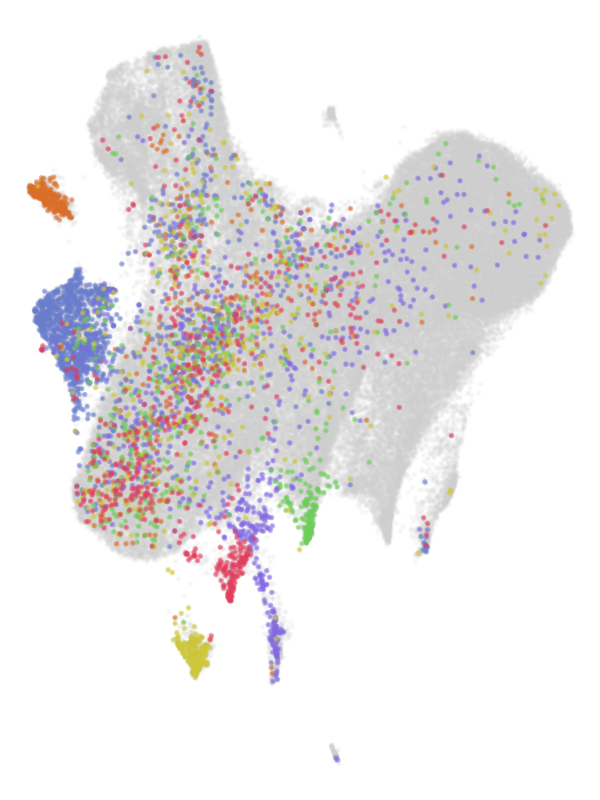

In [4]:
c_pal <- c("#dc6e29", "#6a7fce", "#826be5","#6fcd59", "#cec83a", "#e33f5d")

gRNA_<- multiple_tf_umap_ordered(c("Sox5", "Cdx2","Sox7", "Pax3","Sox10","Neurod1"),
                         "TFallumap",
                         c_pal,
                         "gRNA",
                         1.5)

gRNA_ <- gRNA_ + theme(legend.position="none")
options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
gRNA_

### Figure 2D
Top 6 TF expression distributions in ATAC UMAP

Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."


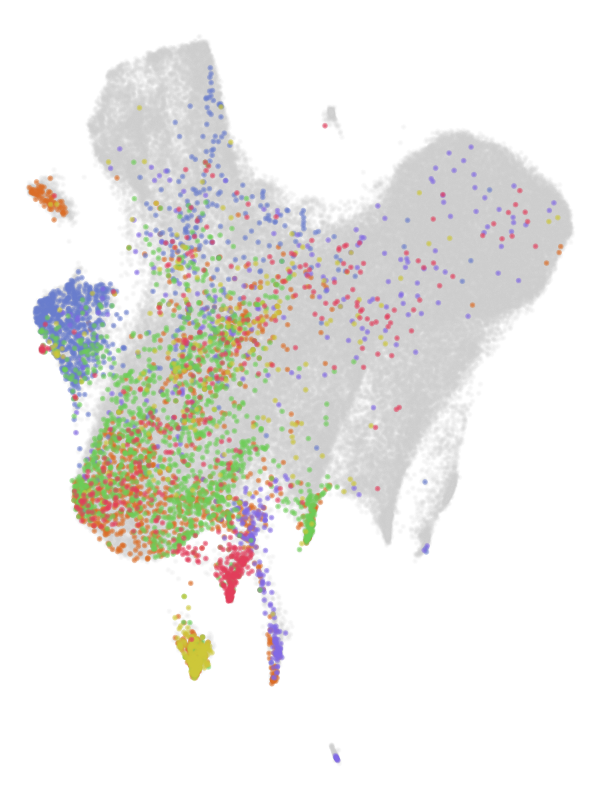

In [5]:
exp_ <- multiple_tf_umap_ordered(c("Sox5", "Cdx2","Sox7", "Pax3","Sox10","Neurod1"),
                         "TFallumap",
                         c_pal,
                         "exp",
                         2)
exp_ <- exp_ + theme(legend.position="none")
options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
exp_

### Figure 2B
Distribution of NTC gRNAs in the ATAC UMAP

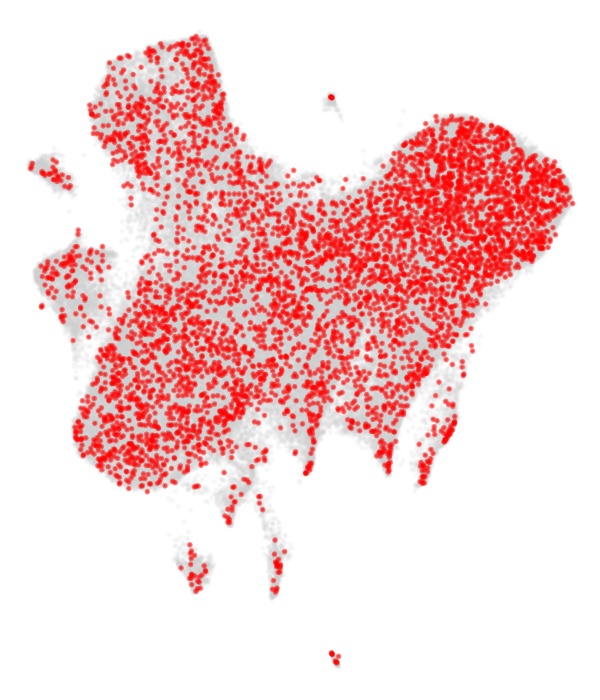

In [6]:
options(repr.plot.width=3, repr.plot.height=3.5, repr.plot.res=200)
ntc <- cells_UMAP(obj,
           obj@meta.data[obj@meta.data$target == "NTC",]$CBC,
           "red","TFallumap") +
      theme(text = element_text(size = 8),
            plot.title = element_text(hjust = 0.5))

ntc

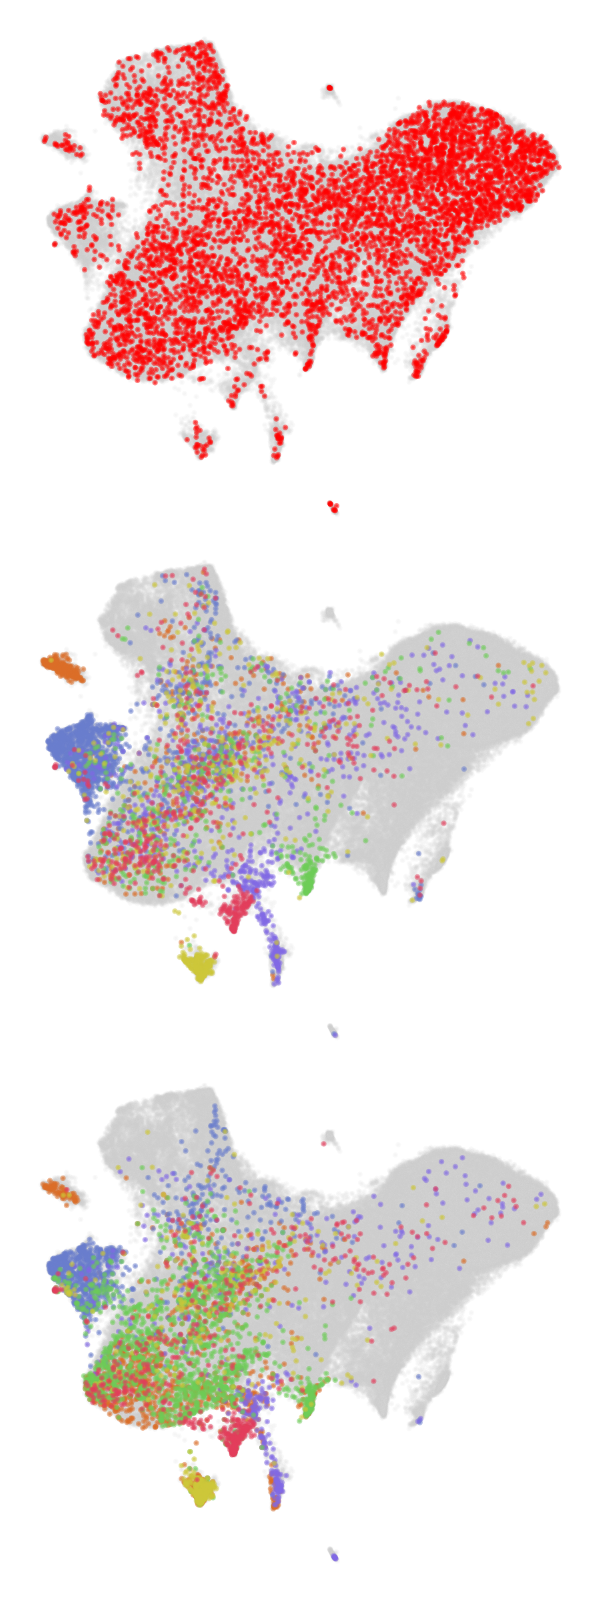

In [7]:
options(repr.plot.width=3, repr.plot.height=8, repr.plot.res=200)

layout <- "
A
B
C
"

fig2bd <- ntc + gRNA_ + exp_ +
  plot_layout(
    design = layout
  ) 
fig2bd

### Figure 2E
Read pileups

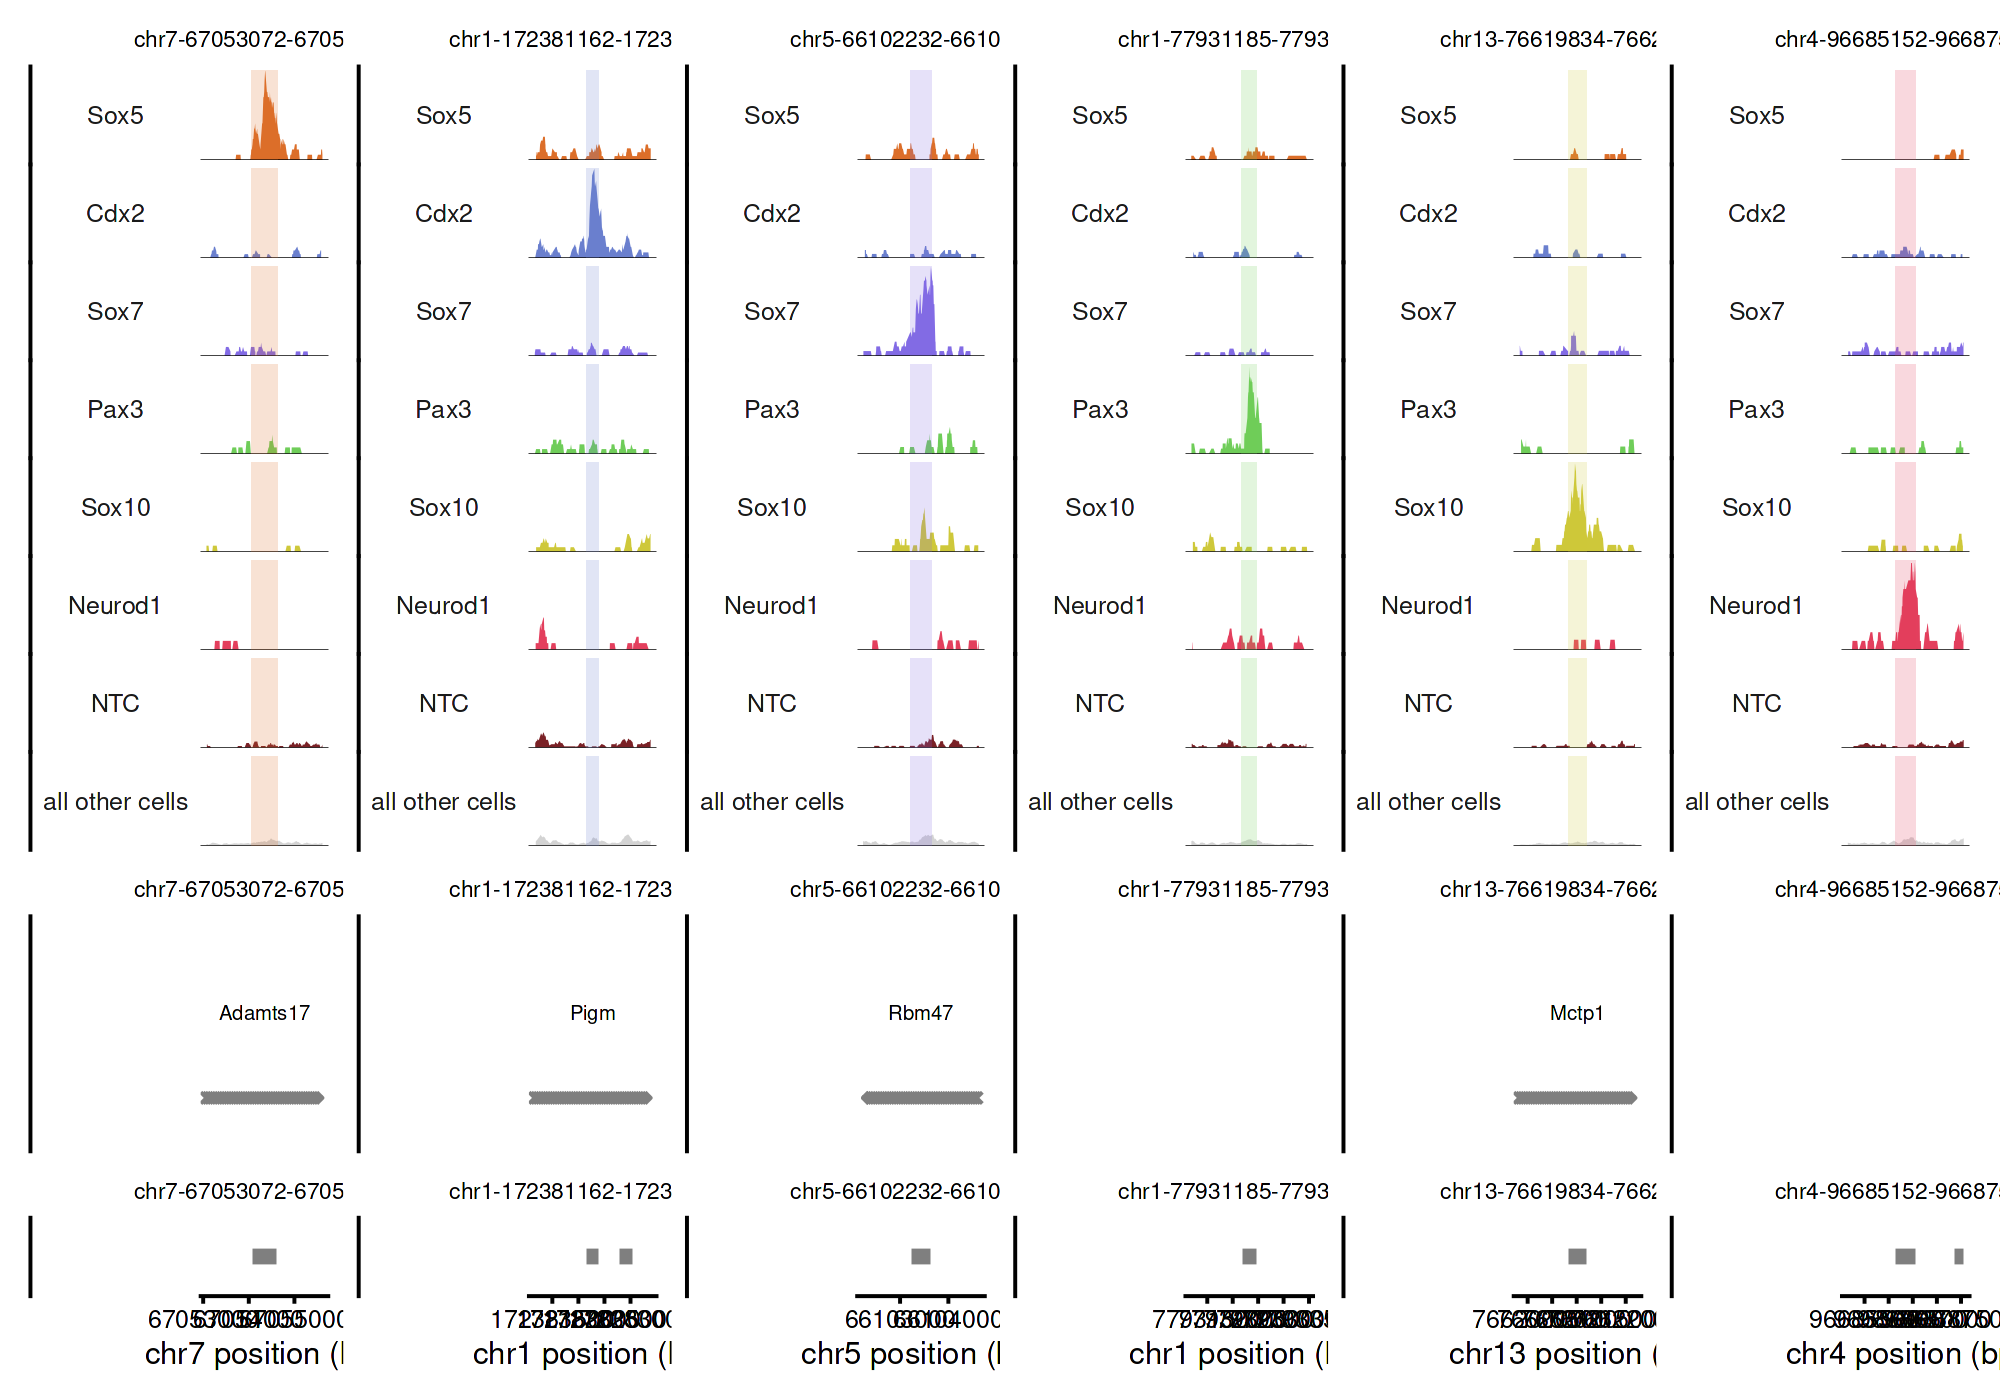

In [8]:
options(warn = -1)
suppressMessages({
    
# -------------------------
# Define groups
# -------------------------
obj@meta.data$group <- "all other cells"

tfs <- c("Sox5", "Cdx2", "Sox7", "Pax3", "Sox10", "Neurod1")

for (tf in tfs) {

  loch <- target_lochNESS(obj, tf)

  t.cells <- rownames(
    loch[loch$genotype == "KO" & loch$raw_mt_score > 1, ]
  )

  obj@meta.data$group <- ifelse(
    rownames(obj@meta.data) %in% t.cells,
    tf,
    obj@meta.data$group
  )
}

obj@meta.data$group <- ifelse(
  obj@meta.data$target == "NTC",
  "NTC",
  obj@meta.data$group
)

# -------------------------
# Set colors/order
# -------------------------
group_cols <- c(
  "Sox5" = "#dc6e29",
  "Cdx2" = "#6a7fce",
  "Sox7" = "#826be5",
  "Pax3" = "#6fcd59",
  "Sox10" = "#cec83a",
  "Neurod1" = "#e33f5d",
  "NTC" = "#7a2126",
  "all other cells" = "lightgrey"
)

obj@meta.data$group <- factor(
  obj@meta.data$group,
  levels = names(group_cols)
)

Idents(obj) <- "group"
DefaultAssay(obj) <- "tf.all.peaks"

# -------------------------
# Regions
# -------------------------
regions <- c(
  "chr7-67053072-67055615",
  "chr1-172381162-172383388",
  "chr5-66102232-66104634",
  "chr1-77931185-77933465",
  "chr13-76619834-76622199",
  "chr4-96685152-96687557"  
  #"chr14-67241500-67242500", -- EBF2
)
    
# -------------------------
# Peaks
# -------------------------    
 peaks <- c(
   "chr7-67054072-67054615",
   "chr1-172382162-172382388",
   "chr5-66103232-66103634",  
     "chr1-77932185-77932465",
    "chr13-76620834-76621199",
     "chr4-96686152-96686557"  
 )   

# -------------------------
# Make individual coverage plots
# -------------------------  
names(peaks) <- regions
names(tfs) <- regions

cov_plots <- lapply(regions, function(region_) {

  peak_ <- StringToGRanges(peaks[[region_]])
  tf_ <- tfs[[region_]]
  peak_$color <- group_cols[[tf_]]

  p <- CoveragePlot(
    object = obj,
    region = region_,
    region.highlight = peak_
  )

  p <- p &
    scale_fill_manual(values = group_cols, drop = FALSE) &
    scale_color_manual(values = group_cols, drop = FALSE) &
    ggtitle(region_) &
    theme(
      plot.title = element_text(hjust = 0.5, size = 8),
      legend.position = "none",
      axis.title.y = element_blank(),
      axis.text.y = element_blank(),
      axis.ticks.y = element_blank()
    )

  p
})

# -------------------------
# Assemble with patchwork
# -------------------------
layout <- "
ABCDEF
"

fig_cov <- wrap_plots(cov_plots, design = layout)

options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 200)
fig_cov
})

In [9]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] ggrastr_1.0.2                      nullranges_1.8.0                  
 [3] monocle3_1.3.5                     SingleCellExperiment_1